# DATA 202 Final Project: Does Payroll Buy Wins?
## Notebook 06: Salary Cap and Floor

**Students:** Asher Ring & Elliot Asquith

**What this notebook does:** Answers our second question, *would a salary cap or floor change who wins?* It applies MLB's proposed \$258.2M cap and \$180.2M floor to the 2026 payrolls, shows who would have to cut or add money, and uses the trend line from notebook 04 to estimate how many wins that would change.

**Reads:** `data/mlb_team_payroll_totals.csv`

**Creates:** `images/cap_and_floor_effect.png`

**Slides it supports:** Introduction (cap and floor), the cap and floor findings slide, Money Raises the Floor

**Where the numbers come from:** MLB proposed a \$258.2M cap and \$180.2M floor on Nov. 3, 2026 (for 2028), after a first proposal of \$245.3M and \$171.2M on May 28, 2026. The players' union instead proposed raising the luxury-tax line to \$300M with a soft floor at half of it (\$150M). The current luxury-tax line for 2026 is \$244M.

**Caution:** MLB measures payroll its luxury-tax way (average contract value plus benefits). We use what teams actually paid in 2026, so our counts differ from MLB's (MLB says 8 teams over the cap and 12 under the floor).

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

DATA_DIR = Path("data")
IMG_DIR = Path("images")
IMG_DIR.mkdir(exist_ok=True)

from statsmodels.formula.api import ols

teams = pd.read_csv(DATA_DIR / "mlb_team_payroll_totals.csv")
teams["payroll_m"] = teams["total_payroll"] / 1e6
teams["games"] = teams["wins"] + teams["losses"]

CAP = 258.2     # $ millions, MLB proposal of Nov. 3, 2026
FLOOR = 180.2

### Who is over the cap, and who is under the floor?

In [2]:
over_cap = teams[teams["payroll_m"] > CAP].copy()
under_floor = teams[teams["payroll_m"] < FLOOR].copy()
over_cap["must_cut_m"] = over_cap["payroll_m"] - CAP
under_floor["must_add_m"] = FLOOR - under_floor["payroll_m"]

ROUND = {"payroll_m": 1, "must_cut_m": 1, "must_add_m": 1}
print(f"Over the ${CAP}M cap: {len(over_cap)} teams, must cut ${over_cap['must_cut_m'].sum():.1f}M combined")
display(over_cap[["team", "payroll_m", "must_cut_m", "win_pct"]].round(ROUND))
print(f"Under the ${FLOOR}M floor: {len(under_floor)} teams, must add ${under_floor['must_add_m'].sum():.1f}M combined")
display(under_floor[["team", "payroll_m", "must_add_m", "win_pct"]].round(ROUND))

Over the $258.2M cap: 6 teams, must cut $276.7M combined


,team,payroll_m,must_cut_m,win_pct
0,NYM,346.7,88.5,0.457
1,LAD,339.3,81.1,0.617
2,NYY,308.3,50.1,0.578
3,PHI,292.0,33.8,0.543
4,TOR,276.1,17.9,0.488
5,ATL,263.5,5.3,0.580


Under the $180.2M floor: 15 teams, must add $942.8M combined


,team,payroll_m,must_add_m,win_pct
15,SEA,170.1,10.1,0.469
16,BAL,167.0,13.2,0.491
17,KC,150.4,29.8,0.426
18,MIL,146.7,33.5,0.636
19,CIN,128.2,52.0,0.463
20,COL,121.5,58.7,0.358
21,MIN,115.7,64.5,0.475
22,PIT,106.7,73.5,0.506
23,CHW,103.3,76.9,0.519
24,WSH,101.6,78.6,0.475


### The same check for every proposal

In [3]:
scenarios = [
    {"rule": "MLB latest proposal (Nov 2026)", "cap": 258.2, "floor": 180.2},
    {"rule": "MLB first proposal (May 2026)", "cap": 245.3, "floor": 171.2},
    {"rule": "Current luxury-tax line (taxed, not a cap)", "cap": 244.0, "floor": None},
    {"rule": "Players' union soft floor", "cap": None, "floor": 150.0},
]

rows = []
for s in scenarios:
    row = {"rule": s["rule"], "teams_over_cap": "-", "teams_under_floor": "-"}
    if s["cap"] is not None:
        row["teams_over_cap"] = (teams["payroll_m"] > s["cap"]).sum()
    if s["floor"] is not None:
        row["teams_under_floor"] = (teams["payroll_m"] < s["floor"]).sum()
    rows.append(row)

display(pd.DataFrame(rows))

,rule,teams_over_cap,teams_under_floor
0,MLB latest proposal (Nov 2026),6,15
1,MLB first proposal (May 2026),7,15
2,"Current luxury-tax line (taxed, not a cap)",7,-
3,Players' union soft floor,-,12


### Would it change who wins?

We refit the line from notebook 04 (win % explained by payroll), then push every team's payroll inside the cap and floor with `clip` and compare the wins the line expects over a full 162-game season before and after. This is a rough what-if: it assumes money turns into wins at the 2026 rate.

In [4]:
model = ols("win_pct ~ payroll_m", data=teams).fit()

teams["capped_m"] = teams["payroll_m"].clip(lower=FLOOR, upper=CAP)
teams["expected_wins_now"] = model.predict(teams) * 162
teams["expected_wins_capped"] = model.predict(teams.assign(payroll_m=teams["capped_m"])) * 162
teams["win_change"] = teams["expected_wins_capped"] - teams["expected_wins_now"]

changed = teams[teams["win_change"].abs() > 0].sort_values("win_change")
display(changed[["team", "payroll_m", "capped_m", "win_change"]].round(1))

print(f"Biggest change for any team: {teams['win_change'].abs().max():.1f} wins")
now_gap = teams["expected_wins_now"].max() - teams["expected_wins_now"].min()
capped_gap = teams["expected_wins_capped"].max() - teams["expected_wins_capped"].min()
print(f"Gap between the most and fewest expected wins: {now_gap:.1f} now -> {capped_gap:.1f} with the cap and floor")
print(f"Actual 2026 wins ranged from {teams['wins'].min()} to {teams['wins'].max()} ({teams['wins'].max() - teams['wins'].min()} games)")

,team,payroll_m,capped_m,win_change
0,NYM,346.7,258.2,-3.7
1,LAD,339.3,258.2,-3.4
2,NYY,308.3,258.2,-2.1
3,PHI,292.0,258.2,-1.4
4,TOR,276.1,258.2,-0.7
5,ATL,263.5,258.2,-0.2
15,SEA,170.1,180.2,0.4
16,BAL,167.0,180.2,0.5
17,KC,150.4,180.2,1.2
18,MIL,146.7,180.2,1.4


Biggest change for any team: 4.4 wins
Gap between the most and fewest expected wins: 11.4 now -> 3.3 with the cap and floor
Actual 2026 wins ranged from 58 to 103 (45 games)


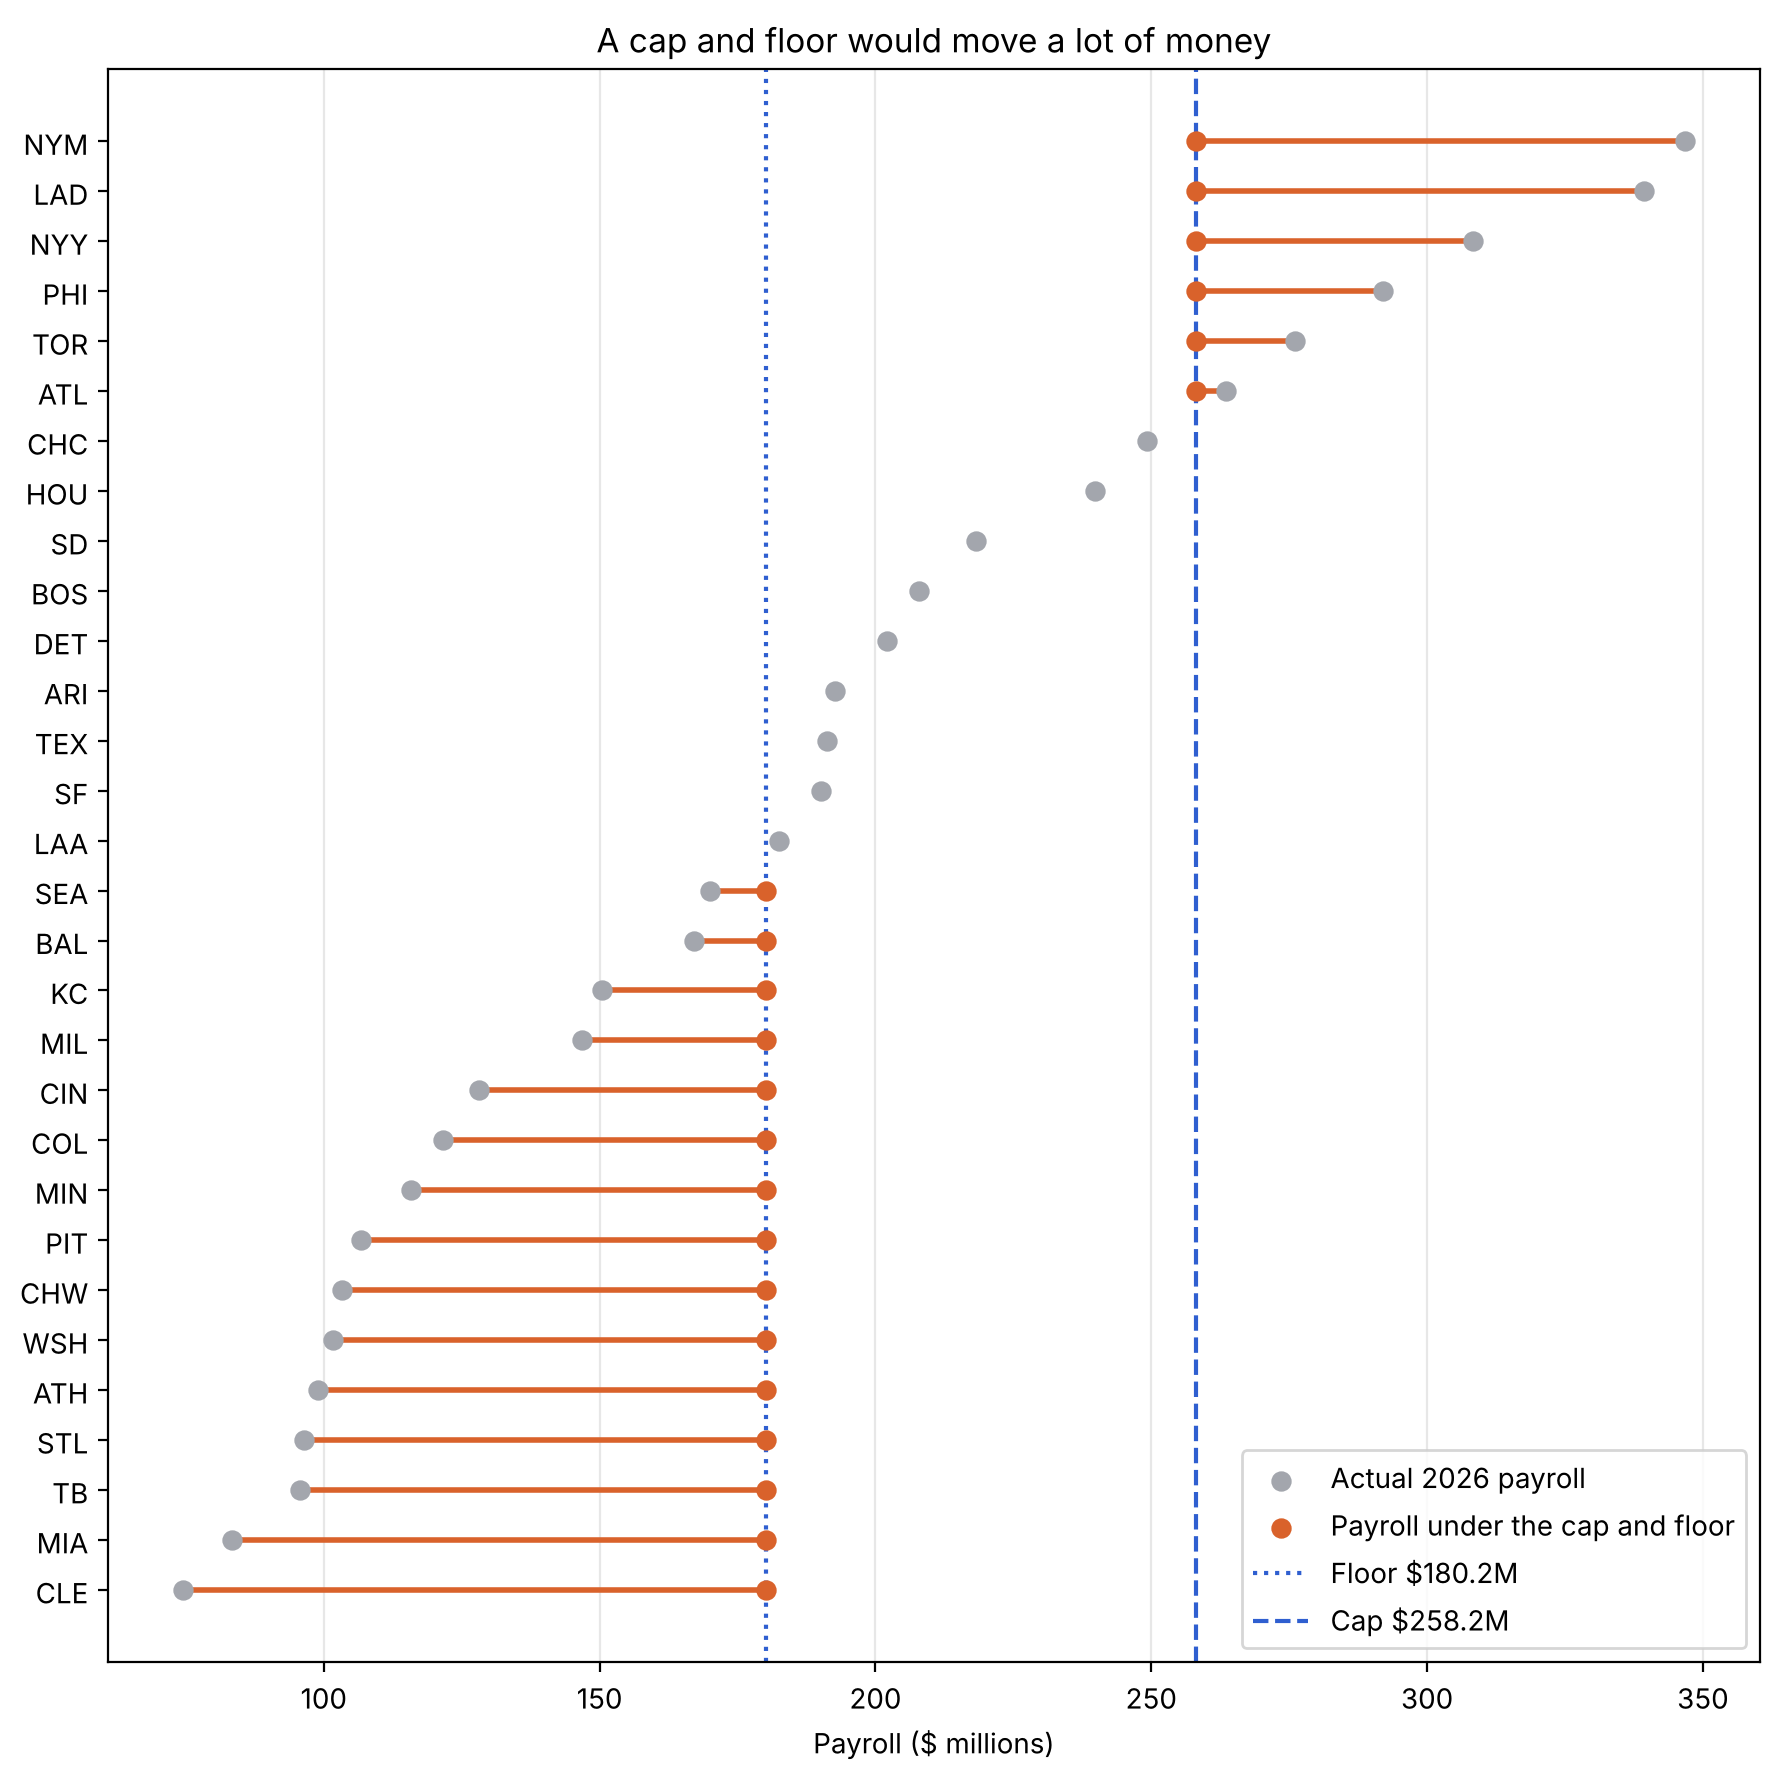

In [5]:
plot_df = teams.sort_values("payroll_m")
fig, ax = plt.subplots(figsize=(9, 9))
moved = plot_df["payroll_m"] != plot_df["capped_m"]
ax.hlines(plot_df["team"], plot_df["payroll_m"], plot_df["capped_m"], color="#D9622B", linewidth=2)
ax.scatter(plot_df["payroll_m"], plot_df["team"], color="#A3A6AD", s=40, zorder=3, label="Actual 2026 payroll")
ax.scatter(plot_df.loc[moved, "capped_m"], plot_df.loc[moved, "team"], color="#D9622B", s=40, zorder=3,
           label="Payroll under the cap and floor")
ax.axvline(FLOOR, color="#2F5FD0", linestyle=":", label=f"Floor ${FLOOR}M")
ax.axvline(CAP, color="#2F5FD0", linestyle="--", label=f"Cap ${CAP}M")
ax.set_title("A cap and floor would move a lot of money")
ax.set_xlabel("Payroll ($ millions)")
ax.legend(loc="lower right")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(IMG_DIR / "cap_and_floor_effect.png", dpi=200)
plt.show()

### How did teams over the cap and under the floor actually do?

In [6]:
teams["group"] = "In between"
teams.loc[teams["payroll_m"] > CAP, "group"] = "Over the cap"
teams.loc[teams["payroll_m"] < FLOOR, "group"] = "Under the floor"
display(teams.groupby("group")["win_pct"].agg(teams="size", avg_win_pct="mean").round(3))

,teams,avg_win_pct
group,,
In between,9,0.492
Over the cap,6,0.544
Under the floor,15,0.487


### Does money raise the floor? (takeaway slide)

In [7]:
top7 = teams.nlargest(7, "payroll_m")
worst4 = teams.nsmallest(4, "win_pct")
print(f"Lowest win % among the 7 biggest payrolls: {top7['win_pct'].min():.3f} ({top7.loc[top7['win_pct'].idxmin(), 'team']})")
print("The 4 worst teams:")
display(worst4[["team", "win_pct", "payroll_m"]].round({"payroll_m": 1}))
print(f"The most any of them spent: ${worst4['payroll_m'].max():.1f}M")

Lowest win % among the 7 biggest payrolls: 0.457 (NYM)
The 4 worst teams:


,team,win_pct,payroll_m
20,COL,0.358,121.5
14,LAA,0.383,182.5
25,ATH,0.395,98.9
13,SF,0.401,190.2


The most any of them spent: $190.2M


### Money tied up in players who are gone, compared with the cap and floor

In [8]:
teams["gone_m"] = (teams["dead_money"] + teams["retained_payroll"]) / 1e6
ten = pd.concat([teams.nlargest(5, "payroll_m"), teams.nsmallest(5, "payroll_m")])
ten = ten[["team", "wins", "payroll_m", "gone_m"]].copy()
ten["share_of_payroll"] = ten["gone_m"] / ten["payroll_m"]
display(ten.round({"payroll_m": 1, "gone_m": 1, "share_of_payroll": 2}))

nym_gone = teams.loc[teams["team"] == "NYM", "gone_m"].iloc[0]
stl_gone = teams.loc[teams["team"] == "STL", "gone_m"].iloc[0]
print(f"Mets: ${nym_gone:.1f}M paid to players who are gone = {nym_gone / CAP:.0%} of the proposed cap")
print(f"Cardinals: ${stl_gone:.1f}M = {stl_gone / FLOOR:.0%} of the proposed floor")

,team,wins,payroll_m,gone_m,share_of_payroll
0,NYM,74,346.7,94.8,0.27
1,LAD,100,339.3,4.1,0.01
2,NYY,93,308.3,30.3,0.10
3,PHI,88,292.0,42.0,0.14
4,TOR,79,276.1,47.4,0.17
29,CLE,85,74.5,6.1,0.08
28,MIA,80,83.3,26.9,0.32
27,TB,98,95.6,9.2,0.10
26,STL,77,96.4,63.7,0.66
25,ATH,64,98.9,11.8,0.12


Mets: $94.8M paid to players who are gone = 37% of the proposed cap
Cardinals: $63.7M = 35% of the proposed floor


*What this shows:* the proposed cap and floor would move about \$1.2 billion between teams, but because payroll explains so little of winning, no team's expected wins would change by more than about 4. Spending more does keep teams out of the very bottom: none of the seven biggest payrolls finished below .457, and the four worst teams all spent \$190.2M or less.